In [1]:
#import py3Dmol
import MDAnalysis as mda
import numpy as np
#import pandas as pd
#u=mda.Universe("step4.1_equilibration.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
#from sklearn.cluster import KMeans
#from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import argparse
import random
#from torchvision import datasets, t:wransforms
from torch.utils.data.sampler import SubsetRandomSampler
import torch.utils.data
from scipy.io import loadmat
from backend_GMVAE.backend_GMVAE import GMVAE
import matplotlib.pyplot as plt


def calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection):
    # Load the topology and trajectory files
    u = mda.Universe(topology_file, trajectory_file)

    # Select the protein residues and ligand atoms
    protein_residues = u.select_atoms(protein_selection)
    ligand_atoms = u.select_atoms(ligand_selection)

    # Create an empty list to store the distances
    num_residues=len(protein_residues)
    avg_distance=np.zeros(num_residues)

    # Iterate over all frames in the trajectory
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist = distances.distance_array(protein_residues.positions, ligand_atoms.positions)

        # Average the distances for each residue
        avg_dist_per_residue = dist.mean(axis=1)

        # Add the average distances to the overall list
        avg_distance=np.add(avg_distance,avg_dist_per_residue)

    # Calculate the overall average distance
    average_distance = avg_distance / len(u.trajectory)

    return average_distance
def silly(k,combined_data):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(combined_data)
    label=kmeans.predict(combined_data)
    sc=silhouette_score(combined_data, label)
    print("Silhouette Score for {}:{}".format(k,sc))
    return sc

topology_file = 'protein_ligand.gro'
trajectory_file = 'final_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BGLCA or resname BGLCN'  # Atom selection for the ligand

average_distance = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection)

def standardize_columns(matrix):
    matrix_max = np.max(matrix, axis=0)
    matrix_min = np.min(matrix, axis=0)
    standardized_matrix = (matrix - mean) / std
    return standardized_matrix



def find_elements_less_than(arr, threshold):
    indices = np.where(arr < threshold)[0]
    elements = arr[indices]
    return indices, elements

# Example usage
threshold_value = 20
indices, elements = find_elements_less_than(average_distance, threshold_value)
print("Indices:", indices)
print("Elements:", elements)

selection = u.select_atoms(f"name CA and resid {' '.join(map(str, indices))}")
selection_1=u.select_atoms("resname BGLCN and resid 1")
selection_2=u.select_atoms("resname BGLCA and resid 2")
selection_3=u.select_atoms("resname BGLCN and resid 3")
selection_4=u.select_atoms("resname BGLCA and resid 4")
selection_5=u.select_atoms("resname BGLCN and resid 5")
selection_6=u.select_atoms("resname BGLCA and resid 6")
selection_7=u.select_atoms("resname BGLCN and resid 7")
selection_8=u.select_atoms("resname BGLCA and resid 8")
data=[]
print ("yes")
for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
    dist_1 = distances.distance_array(selection.positions, selection_1.positions)
    dist_2 = distances.distance_array(selection.positions, selection_2.positions)
    dist_3 = distances.distance_array(selection.positions, selection_3.positions)
    dist_4 = distances.distance_array(selection.positions, selection_4.positions)
    dist_5 = distances.distance_array(selection.positions, selection_5.positions)
    dist_6 = distances.distance_array(selection.positions, selection_6.positions)
    dist_7 = distances.distance_array(selection.positions, selection_7.positions)
    dist_8 = distances.distance_array(selection.positions, selection_8.positions)
    avg_dist_per_residue_1 = dist_1.mean(axis=1)
    avg_dist_per_residue_2 = dist_2.mean(axis=1)
    avg_dist_per_residue_3 = dist_3.mean(axis=1)
    avg_dist_per_residue_4 = dist_4.mean(axis=1)
    avg_dist_per_residue_5 = dist_5.mean(axis=1)
    avg_dist_per_residue_6 = dist_6.mean(axis=1)
    avg_dist_per_residue_7 = dist_7.mean(axis=1)
    avg_dist_per_residue_8 = dist_8.mean(axis=1)
    final_array=np.concatenate((avg_dist_per_residue_1, avg_dist_per_residue_2, avg_dist_per_residue_3, avg_dist_per_residue_4, avg_dist_per_residue_5, avg_dist_per_residue_6, avg_dist_per_residue_7, avg_dist_per_residue_8))
    data.append(final_array)
combined_data=np.stack(data,axis=0)
print ("yes")
print(combined_data.shape)
def standardize_columns(matrix):
    mean = np.max(matrix, axis=0)
    std = np.min(matrix, axis=0)
    standardized_matrix = (matrix - std) / (mean-std)
    return standardized_matrix

# Example usage
combined_data = standardize_columns(combined_data)
parser = argparse.ArgumentParser(description='PyTorch Implementation of DGM Clustering')

## Used only in notebooks
parser.add_argument('-f', '--file', help='Path for input file. First line should contain number of lines to search in')

## Dataset
parser.add_argument('--seed', type=int, default=1, help='random seed (default: 1)')

## GPU
parser.add_argument('--cuda', type=int, default=1, help='use of cuda (default: 1)')
parser.add_argument('--gpuID', type=int, default=0, help='set gpu id to use (default: 0)')

## Training
parser.add_argument('--epochs', type=int, default=100, help='number of total epochs to run (default: 200)')
parser.add_argument('--batch_size', default=64, type=int, help='mini-batch size (default: 64)')
parser.add_argument('--batch_size_val', default=200, type=int, help='mini-batch size of validation (default: 200)')
parser.add_argument('--learning_rate', default=1e-4, type=float, help='learning rate (default: 0.001)')
parser.add_argument('--decay_epoch', default=-1, type=int, help='Reduces the learning rate every decay_epoch')
parser.add_argument('--lr_decay', default=0.5, type=float, help='Learning rate decay for training (default: 0.5)')

## Architecture
parser.add_argument('--num_classes', type=int, default=3, help='number of classes (default: 10)')
parser.add_argument('--gaussian_size', default=64, type=int, help='gaussian size (default: 64)')
parser.add_argument('--input_size', default=combined_data.shape[1], type=int, help='input size (default: 784)')
parser.add_argument('--train_proportion', default=1.0, type=float, help='proportion of examples to consider for training only (default: 1.0)')


## Gumbel parameters
parser.add_argument('--init_temp', default=1.0, type=float, help='Initial temperature used in gumbel-softmax (recommended 0.5-1.0, default:1.0)')
parser.add_argument('--decay_temp', default=1, type=int, help='Set 1 to decay gumbel temperature at every epoch (default: 1)')
parser.add_argument('--hard_gumbel', default=0, type=int, help='Set 1 to use the hard version of gumbel-softmax (default: 1)')
parser.add_argument('--min_temp', default=0.5, type=float, help='Minimum temperature of gumbel-softmax after annealing (default: 0.5)' )
parser.add_argument('--decay_temp_rate', default=0.013862944, type=float, help='Temperature decay rate at every epoch (default: 0.013862944)')

## Loss function parameters
parser.add_argument('--w_gauss', default=2, type=float, help='weight of gaussian loss (default: 1)')
parser.add_argument('--w_categ', default=1, type=float, help='weight of categorical loss (default: 1)')
parser.add_argument('--w_rec', default=1, type=float, help='weight of reconstruction loss (default: 1)')
parser.add_argument('--rec_type', type=str, choices=['bce', 'mse'],default='bce', help='desired reconstruction loss function (default: bce)')
#combined_data=(combined_data - np.min(combined_data)) / (np.max(combined_data)-np.min(combined_data))
parser.add_argument('--verbose', default=1, type=int, help='print extra information at every epoch.(default: 0)')

args = parser.parse_args()
## Random Seed
SEED = args.seed
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)
if args.cuda:
  torch.cuda.manual_seed(SEED)
def partition_dataset(n, proportion=0.8):
  train_num = int(n * proportion)
  indices = np.random.permutation(n)
  train_indices, val_indices = indices[:train_num], indices[train_num:]
  return train_indices, val_indices
train_dataset=combined_data
test_dataset=combined_data
if args.train_proportion == 1.0:
  # we use all train dataset without partitioning
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True)
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
  val_loader = test_loader
else:
  # partition dataset according to train_proportion
  train_indices, val_indices = partition_dataset(len(train_dataset), args.train_proportion)
  # create data loaders for train, validation and test datasets
  train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size, sampler=SubsetRandomSampler(train_indices))
  val_loader = torch.utils.data.DataLoader(train_dataset, batch_size=args.batch_size_val, sampler=SubsetRandomSampler(val_indices))
  test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=args.batch_size_val, shuffle=False)
gmvae = GMVAE(args)
history_loss = gmvae.train(train_loader,val_loader)
test_loss,recon_test,gauss_test,cat_test, labels_test=gmvae.test(test_loader)
print (labels_test)
np.save("labels_test.npy",labels_test)

/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Indices: [ 13  14  15  16  17  18  19  20  21  22  23  24  25  26  27  29  30  33
  34  37  86  87  88  89  90  91  92  93  94  95  96  97 141 142 143 144
 145 146 147 148 149 150 189 190 191 192 193 194 195 196 197 198 199 200
 201 202 203 204 205 206 207 255 256 257 258 290]
Elements: [18.30572661 17.51484307 15.6183295  14.52043698 14.20571594 14.87891169
 15.95908964 16.54760409 17.43823816 15.94935998 16.69239247 16.30933885
 16.23987931 18.7671919  19.54875119 19.01329052 17.48440343 18.1988125
 19.16616064 19.96128936 19.09723671 17.36266088 14.73863095 15.25175828
 14.29665437 16.86080798 17.04447629 15.14868241 16.48376563 19.03842767
 18.40772301 17.84646004 17.99520968 17.07740674 18.10202355 16.43937635
 15.3101562  14.9551541  17.64338935 18.64293788 17.73088402 19.34821294
 17.4936245  16.28254122 18.42494718 17.68796294 15.28909144 16.9768802
 17.02734332 14.90809017 16.19164675 17.62308791 15.40683014 14.50825486
 17.19395479 17.30264395 15.29635928 16.76764599 19.34607

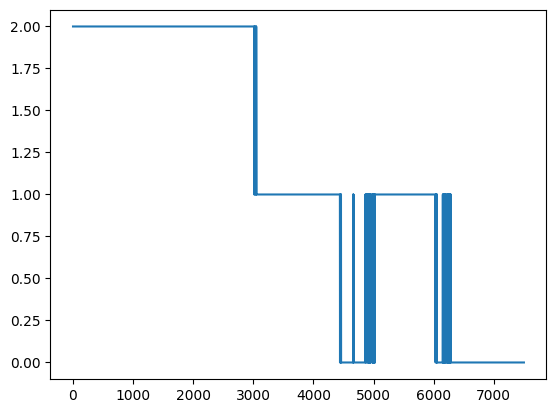

In [2]:
arr=np.arange(1,7502) 
labels_test=np.load("labels_test.npy")
plt.plot(arr,labels_test)
plt.savefig("GMVAE_clusters.jpg")

In [12]:
!ls

backend_GMVAE						    slurm-2853978.out
bin							    slurm-2854553.out
charmm-gui-Asp-123					    slurm-2854558.out
charmm-gui-no-Asp					    slurm-2855309.out
cuda-repo-debian11-11-8-local_11.8.0-520.61.05-1_amd64.deb  slurm-2855541.out
cuda-repo-rhel7-11-8-local-11.8.0_520.61.05-1.x86_64.rpm    slurm-2856596.out
dyn.csh							    slurm-2856618.out
dysamplegeneration.sh					    slurm-2856627.out
final_production.xtc					    slurm-2856651.out
first-dyn.csh						    slurm-2856657.out
fourha.pdb						    slurm-2856658.out
GMVAE.py						    slurm-2856666.out
gromacs-2019.4						    slurm-2856681.out
H221F_fourha						    slurm-2856814.out
H221F_hexamana						    slurm-2859167.out
H221F_tetraha						    slurm-2859190.out
hexamana						    slurm-2859211.out
include							    slurm-2859462.out
lib64							    slurm-2860484.out
miniconda						    slurm-2860485.out
miniconda.sh						    slurm-2860486.out
ML.yml							    slurm-2860627.out
protein_ligand.gro					    slurm-2860631.out
py3.py		

/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Indices: [ 13  14  15  16  17  18  19  20  21  22  23  24  25  26  27  29  30  33
  34  37  86  87  88  89  90  91  92  93  94  95  96  97 141 142 143 144
 145 146 147 148 149 150 189 190 191 192 193 194 195 196 197 198 199 200
 201 202 203 204 205 206 207 255 256 257 258 290]
Elements: [18.30572661 17.51484307 15.6183295  14.52043698 14.20571594 14.87891169
 15.95908964 16.54760409 17.43823816 15.94935998 16.69239247 16.30933885
 16.23987931 18.7671919  19.54875119 19.01329052 17.48440343 18.1988125
 19.16616064 19.96128936 19.09723671 17.36266088 14.73863095 15.25175828
 14.29665437 16.86080798 17.04447629 15.14868241 16.48376563 19.03842767
 18.40772301 17.84646004 17.99520968 17.07740674 18.10202355 16.43937635
 15.3101562  14.9551541  17.64338935 18.64293788 17.73088402 19.34821294
 17.4936245  16.28254122 18.42494718 17.68796294 15.28909144 16.9768802
 17.02734332 14.90809017 16.19164675 17.62308791 15.40683014 14.50825486
 17.19395479 17.30264395 15.29635928 16.76764599 19.34607

/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 2:0.2711820233356324


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 3:0.3336947211797095


... (29 outputs left out)

Silhouette Score for 18:0.25927386993354146


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


Silhouette Score for 19:0.25523611317250233


/expanse/lustre/projects/mda123/kmondal/miniconda/envs/ML/lib/python3.10/site-packages/sklearn/cluster/_kmeans.py:1412: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  super()._check_params_vs_input(X, default_n_init=10)


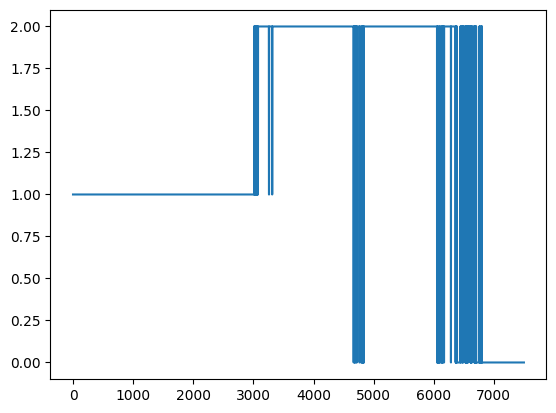

In [1]:
#import py3Dmol
import MDAnalysis as mda
import numpy as np
#import pandas as pd
u=mda.Universe("protein_ligand.gro","final_production.xtc")
from MDAnalysis.analysis import rms, diffusionmap, align
from MDAnalysis.analysis.distances import dist
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA
u=mda.Universe("protein_ligand.gro","final_production.xtc")
import MDAnalysis as mda
from MDAnalysis.analysis import distances
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt


def calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection):
    # Load the topology and trajectory files
    u = mda.Universe(topology_file, trajectory_file)

    # Select the protein residues and ligand atoms
    protein_residues = u.select_atoms(protein_selection)
    ligand_atoms = u.select_atoms(ligand_selection)

    # Create an empty list to store the distances
    num_residues=len(protein_residues)
    avg_distance=np.zeros(num_residues)

    # Iterate over all frames in the trajectory
    for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
        dist = distances.distance_array(protein_residues.positions, ligand_atoms.positions)

        # Average the distances for each residue
        avg_dist_per_residue = dist.mean(axis=1)

        # Add the average distances to the overall list
        avg_distance=np.add(avg_distance,avg_dist_per_residue)

    # Calculate the overall average distance
    average_distance = avg_distance / len(u.trajectory)

    return average_distance

def silly(k,combined_data):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(combined_data)
    label=kmeans.predict(combined_data)
    sc=silhouette_score(combined_data, label)
    print("Silhouette Score for {}:{}".format(k,sc))
    return sc
topology_file = 'protein_ligand.gro'
trajectory_file = 'final_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BGLCA or resname BGLCN'  # Atom selection for the ligand
def silly(k,combined_data):
    kmeans=KMeans(n_clusters=k)
    kmeans.fit(combined_data)
    label=kmeans.predict(combined_data)
    sc=silhouette_score(combined_data, label)
    print("Silhouette Score for {}:{}".format(k,sc))
    return sc







# Example usage
topology_file = 'protein_ligand.gro'
trajectory_file = 'final_production.xtc'
protein_selection = 'name CA and protein'  # Atom selection for the protein residues
ligand_selection = 'resname BGLCA or resname BGLCN'  # Atom selection for the ligand

average_distance = calculate_average_distance(topology_file, trajectory_file, protein_selection, ligand_selection)

def find_elements_less_than(arr, threshold):
    indices = np.where(arr < threshold)[0]
    elements = arr[indices]
    return indices, elements

# Example usage
threshold_value = 20
indices, elements = find_elements_less_than(average_distance, threshold_value)
print("Indices:", indices)
print("Elements:", elements)

selection = u.select_atoms(f"name CA and resid {' '.join(map(str, indices))}")
selection_1=u.select_atoms("resname BGLCN and resid 1")
selection_2=u.select_atoms("resname BGLCA and resid 2")
selection_3=u.select_atoms("resname BGLCN and resid 3")
selection_4=u.select_atoms("resname BGLCA and resid 4")
selection_5=u.select_atoms("resname BGLCN and resid 5")
selection_6=u.select_atoms("resname BGLCA and resid 6")
selection_7=u.select_atoms("resname BGLCN and resid 7")
selection_8=u.select_atoms("resname BGLCA and resid 8")
data=[]
print ("yes")
for ts in u.trajectory:
        # Calculate distances between protein residues and ligand atoms
    dist_1 = distances.distance_array(selection.positions, selection_1.positions)
    dist_2 = distances.distance_array(selection.positions, selection_2.positions)
    dist_3 = distances.distance_array(selection.positions, selection_3.positions)
    dist_4 = distances.distance_array(selection.positions, selection_4.positions)
    dist_5 = distances.distance_array(selection.positions, selection_5.positions)
    dist_6 = distances.distance_array(selection.positions, selection_6.positions)
    dist_7 = distances.distance_array(selection.positions, selection_7.positions)
    dist_8 = distances.distance_array(selection.positions, selection_8.positions)
    avg_dist_per_residue_1 = dist_1.mean(axis=1)
    avg_dist_per_residue_2 = dist_2.mean(axis=1)
    avg_dist_per_residue_3 = dist_3.mean(axis=1)
    avg_dist_per_residue_4 = dist_4.mean(axis=1)
    avg_dist_per_residue_5 = dist_5.mean(axis=1)
    avg_dist_per_residue_6 = dist_6.mean(axis=1)
    avg_dist_per_residue_7 = dist_7.mean(axis=1)
    avg_dist_per_residue_8 = dist_8.mean(axis=1)
    final_array=np.concatenate((avg_dist_per_residue_1, avg_dist_per_residue_2, avg_dist_per_residue_3, avg_dist_per_residue_4, avg_dist_per_residue_5, avg_dist_per_residue_6, avg_dist_per_residue_7, avg_dist_per_residue_8))
    data.append(final_array)
combined_data=np.stack(data,axis=0)
print ("yes")
print(combined_data.shape)
no=[]
score=[]
for j in range (2,20):
    sc=silly(j,combined_data)
    score.append(sc)
    no.append(j)

max_element=max(score)
max_index=score.index(max_element)
m_index=max_index+2
kmeans=KMeans(n_clusters=m_index)
clusters = kmeans.fit(combined_data)
x=[]
for i in range (0,len(u.trajectory)):

    j=j+1
    x.append(i)

plt.plot(x,clusters.labels_)

plt.savefig("K-means_cluster.jpg")

plt.show()

    
